# Teaching a computer to guess "will lunch be good?"

This notebook builds **logistic regression** from scratch, one small step at a time. You only need to know
basic Python and what an average is. No machine-learning library is used: every piece that "learns" is
written out here with NumPy.

**The story.** The mess logged 500 lunches. For each one we know four numbers and whether the lunch was good:

| column | meaning |
|---|---|
| `queue_length` | how many people queued |
| `plate_waste_fraction` | share of food left on plates (0 to 1) |
| `menu_board_kcal` | calories written on the menu board |
| `handwriting_neatness` | how neatly the menu board was written (0 to 10) |
| `good_lunch` | **the answer**: 1 = good, 0 = not good |

**The goal.** Given the four numbers for a new lunch, output a probability that it is good.

The plan: data -> scaling -> sigmoid -> loss -> gradient -> update loop -> evaluate.

## Step 1. Load the data

Each row is one lunch. We keep the four input columns in a table `X` (500 rows x 4 columns) and the
answers in `y` (500 zeros and ones).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The CSV lives two folders up, in datasets/ (run this notebook from its own folder).
DATA_PATH = Path("..") / ".." / "datasets" / "binary_classification.csv"
FEATURES = ["queue_length", "plate_waste_fraction", "menu_board_kcal", "handwriting_neatness"]

df = pd.read_csv(DATA_PATH)
X = df[FEATURES].to_numpy(dtype=float)
y = df["good_lunch"].to_numpy(dtype=float)
print(X.shape, "| share of good lunches:", y.mean())
df.head(3)

(500, 4) | share of good lunches: 0.408


,queue_length,plate_waste_fraction,menu_board_kcal,handwriting_neatness,good_lunch
0,43,0.575,2096,8.2,0
1,37,0.497,1924,5.2,0
2,43,0.348,2280,7.7,1


## Step 2. Hide some lunches for the final exam (train/test split)

If we judge the model on the same lunches it learned from, it can look great just by memorising.
So we shuffle the rows and set 20% aside as a **test set** the model never sees while learning.
The shuffle uses a fixed seed (42) so everyone who runs this gets exactly the same split.

In [2]:
rng = np.random.default_rng(42)          # seeded random number generator
order = rng.permutation(len(y))          # a shuffled list of row numbers
n_test = 100                             # 20% of 500
test_idx, train_idx = order[:n_test], order[n_test:]

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]
print("train:", len(y_train), "rows | test:", len(y_test), "rows")

train: 400 rows | test: 100 rows


## Step 3. Put every column on the same scale

Look at the raw numbers: calories are around **2000**, plate waste is around **0.5**. Gradient descent
takes a step of the same size "learning rate" for every weight, so with raw numbers one step would be
huge for the calories weight and tiny for the waste weight.

The fix is the **z-score**: subtract the column's mean and divide by its standard deviation, so every
column ends up centred at 0 with a spread of about 1.

Important: the mean and standard deviation come from the **training rows only**. The test rows are our
"never seen" lunches, so they must not influence anything, not even the scaling. (Using them would be a
small leak of test information into training.)

In [3]:
mean = X_train.mean(axis=0)   # one mean per column, from TRAIN only
std = X_train.std(axis=0)     # one standard deviation per column, from TRAIN only

X_train_s = (X_train - mean) / std
X_test_s = (X_test - mean) / std   # the test set reuses the TRAIN numbers

print("raw column means:   ", [round(float(m), 2) for m in mean])
# (+ 0.0 just turns a printed "-0." into "0.")
print("scaled column means:", np.round(X_train_s.mean(axis=0), 2) + 0.0, "| scaled stds:", np.round(X_train_s.std(axis=0), 2))

raw column means:    [37.05, 0.46, 2050.77, 5.17]
scaled column means: [0. 0. 0. 0.] | scaled stds: [1. 1. 1. 1.]


## Step 4. Turn a score into a probability: the sigmoid

The model gives each feature a **weight** `w` and adds a **bias** `b`:

$$z = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + b$$

`z` can be any number, but we want a probability between 0 and 1. The **sigmoid** squashes it:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Big positive `z` -> close to 1 ("surely good"), big negative `z` -> close to 0, and `z = 0` -> exactly 0.5.

In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)        # keeps np.exp from overflowing on extreme values
    return 1.0 / (1.0 + np.exp(-z))

def predict_proba(X, w, b):
    return sigmoid(X @ w + b)        # X @ w = weighted sum of each row's features

print(np.round(sigmoid(np.array([-5.0, 0.0, 5.0])), 3))

[0.007 0.5   0.993]


## Step 5. Measure how wrong we are: the loss

We need one number that says how bad the current weights are. We use **binary cross-entropy**:

$$L = -\text{mean}\big(y \log p + (1-y)\log(1-p)\big)$$

For a good lunch (`y = 1`) only `-log p` counts: small if we said `p` near 1, huge if we said `p` near 0.
For a bad lunch only `-log(1-p)` counts. So confident wrong answers are punished hardest.

In [5]:
def bce_loss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)     # never take log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# One good lunch (y = 1): a confident right guess vs a confident wrong guess
print("said 0.9:", round(bce_loss(np.array([1.0]), np.array([0.9])), 3),
      "| said 0.1:", round(bce_loss(np.array([1.0]), np.array([0.1])), 3))

said 0.9: 0.105 | said 0.1: 2.303


## Step 6. Which way is downhill? The gradient

The gradient tells us, for each weight, how the loss changes if we nudge that weight up. For this
model the calculus works out to something short:

$$\frac{\partial L}{\partial w} = \frac{1}{n} X^\top (p - y) \qquad \frac{\partial L}{\partial b} = \text{mean}(p - y)$$

`p - y` is the error on each lunch: positive if we were too optimistic, negative if too pessimistic.
Each weight's gradient is that error, weighted by how big its feature was on each lunch, averaged.

In [6]:
def gradients(X, y, p):
    error = p - y                        # one number per lunch
    grad_w = X.T @ error / len(y)        # one number per feature
    grad_b = error.mean()
    return grad_w, grad_b

## Step 7. Learn: take many small steps downhill

Start with all weights at 0 (every lunch gets p = 0.5, loss = log 2 = 0.693). Then repeat:

1. compute `p` for every training lunch,
2. compute the loss,
3. compute the gradient,
4. move every weight a little **against** the gradient: `w = w - lr * grad_w`.

`lr` (learning rate) sets the step size. Using all training rows in every step is called **batch**
gradient descent.

**When do we stop?** Our convergence criterion: when the loss changes by less than `1e-6` from one step to
the next (it has flattened out), or after 10,000 steps, whichever comes first.

In [7]:
import time

def train(X, y, lr, max_iters=10_000, tol=1e-6):
    w, b = np.zeros(X.shape[1]), 0.0
    losses = []
    for step in range(max_iters):
        p = predict_proba(X, w, b)
        losses.append(bce_loss(y, p))
        if step > 0 and abs(losses[-2] - losses[-1]) < tol:
            break                                  # converged
        grad_w, grad_b = gradients(X, y, p)
        w, b = w - lr * grad_w, b - lr * grad_b    # the update step
    return w, b, losses

start = time.perf_counter()
w, b, losses = train(X_train_s, y_train, lr=0.5)
print(f"stopped after {len(losses) - 1} updates in {1000 * (time.perf_counter() - start):.0f} ms, "
      f"loss {losses[0]:.3f} -> {losses[-1]:.3f}")

stopped after 151 updates in 6 ms, loss 0.693 -> 0.380


## Step 8. The final exam: accuracy on the test set

To turn a probability into a yes/no answer we say "good" when `p >= 0.5`. Accuracy is the share of
test lunches we get right. For context, a lazy model that always says "not good" would score the share of
bad lunches in the test set.

In [8]:
p_test = predict_proba(X_test_s, w, b)
test_accuracy = np.mean((p_test >= 0.5) == y_test)
print(f"test accuracy: {test_accuracy:.2f} | always-'not good' baseline: {1 - y_test.mean():.2f}")
print("weights:", {name: round(float(v), 2) for name, v in zip(FEATURES, w)}, "| bias:", round(float(b), 2))

test accuracy: 0.75 | always-'not good' baseline: 0.58
weights: {'queue_length': 1.85, 'plate_waste_fraction': -1.19, 'menu_board_kcal': 0.45, 'handwriting_neatness': 0.26} | bias: -0.68


**Reading the weights** (they are comparable because every feature was scaled the same way):
a long queue pushes strongly toward "good", lots of plate waste pushes toward "not good". Calories matter a
little. `handwriting_neatness` gets a small weight even though, across the whole file, it has almost no link
to lunch quality: the model picked up a chance pattern in the training rows. `analysis.md` digs into this.

## Step 9. Why the learning rate matters

Same model, same data, three step sizes. Too small and it crawls; too big and it overshoots the bottom of
the valley and keeps bouncing.

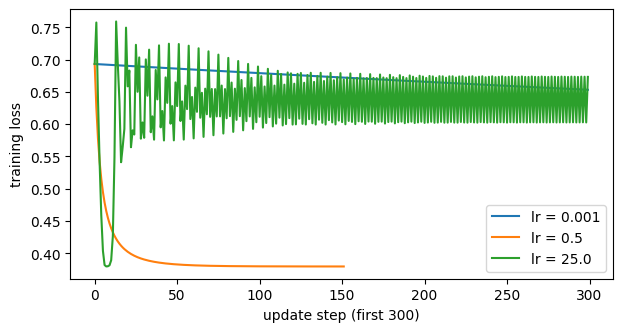

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for lr in [0.001, 0.5, 25.0]:
    _, _, run_losses = train(X_train_s, y_train, lr=lr)
    ax.plot(run_losses[:300], label=f"lr = {lr}")
ax.set_xlabel("update step (first 300)")
ax.set_ylabel("training loss")
ax.legend()
plt.show()

## Recap

| step | idea in one line |
|---|---|
| split | keep 20% of lunches hidden so the final score is honest |
| scale | z-score with train statistics so one learning rate fits every feature |
| sigmoid | squash the weighted sum into a probability |
| loss | binary cross-entropy: punishes confident wrong answers most |
| gradient | `X^T (p - y) / n`: which way each weight should move |
| update | `w = w - lr * gradient`, repeat until the loss stops changing |
| evaluate | accuracy on the hidden test lunches |

The full script (`logistic_regression.py`) runs the same steps plus the learning-rate comparison and the
error analysis.